# Chapter 3: Boolean Algebra Under Noise

Companion notebook for **Chapter 3** of *Bernoulli Types: Two-Sided Error in Approximate Membership, Retrieval, and Computation*.
Source files: `book/chapters/ch03/`.

This notebook:

1. Demonstrates AND, OR, and NOT on noisy bits empirically and compares with closed-form predictions.
2. Shows, with `bernoulli.formula`, why an $(\epsilon, \omega)$ pair does not propagate exactly through a Boolean formula (Section 3.3): the exact object is the error at each latent assignment.
3. Verifies the composition theorem (Section 3.4) on a 5-stage chain: empirical vs theoretical error rates.
4. Implements Miller-Rabin primality testing in ~25 lines as a worked example of `Bernoulli[bool]` composition.
5. Plots empirical false-positive rate (FPR) vs the theoretical `(1/4)^k` bound for `k = 1..20` rounds.
6. Examines what happens when Miller-Rabin witnesses are correlated, motivating the open question deferred to Chapter 16.

**Conventions (matching book notation):**
- `epsilon` (`fpr`) = false-positive rate
- `omega` (`fnr`) = false-negative rate
- Boolean values represented as `True` / `False` (or `1` / `0` in numpy arrays).
- `eta_i` = per-stage error rate at stage `i` in a composition chain.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Callable

rng = np.random.default_rng(seed=42)

print(f"NumPy {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy 2.5.4
Matplotlib 3.11.2


## 1. AND, OR, and NOT Under Simulated Noise

A `Bernoulli[bool]` instance is a noisy Boolean value characterized by two rates:
- **FPR** (`epsilon`): probability of reporting `True` when the true value is `False`.
- **FNR** (`omega`): probability of reporting `False` when the true value is `True`.

We define helpers that simulate a noisy bit and verify the closed-form output rates
for AND, OR, and NOT derived in Sections 3.1 and 3.2.

### NOT Under Noise

NOT swaps the error rates: if `b` has `(fpr, fnr) = (epsilon, omega)`, then `NOT b` has
`(fpr, fnr) = (omega, epsilon)`. This is the trivial derivation from Section 3.2.

### AND Under Noise

For two independent `Bernoulli[bool]` instances `b1` with `(epsilon_1, omega_1)` and
`b2` with `(epsilon_2, omega_2)`, the AND derivation (Section 3.1) gives:

- **True positive rate of AND** (both inputs truly `True`):
  `tp_and = (1 - omega_1)(1 - omega_2)`

- **False positive contribution from case (True, False)**:
  `(1 - omega_1) * epsilon_2`  (b1 reports correctly, b2 reports incorrectly)

- **False positive contribution from case (False, True)**:
  `epsilon_1 * (1 - omega_2)` (b1 reports incorrectly, b2 reports correctly)

- **False positive contribution from case (False, False)**:
  `epsilon_1 * epsilon_2` (both report incorrectly)

The **FNR of AND** (both inputs truly `True`, but AND reports `False`):
`fnr_and = 1 - (1 - omega_1)(1 - omega_2)`

The **FPR of AND** depends on the input distribution. Under the uniform distribution
over the three negative cases, the expected FPR is a weighted average. See Section 3.1
for the full case analysis. Because the three negative cases have three different
false-positive rates, the AND of two two-rate bits is not itself a two-rate bit;
the next section of this notebook (book Section 3.3) shows what that does to a formula.

### OR via De Morgan

From Section 3.2: `b1 OR b2 = NOT(NOT b1 AND NOT b2)`. Applying the NOT rate-swap
and the AND formula gives the OR rates from the AND rates.

In [2]:
def noisy_bit(true_val: bool, fpr: float, fnr: float, n: int,
              rng: np.random.Generator) -> np.ndarray:
    """Simulate n independent noisy observations of a Boolean value.

    Parameters
    ----------
    true_val : bool
        The underlying true value.
    fpr : float
        False-positive rate: Pr(report True | true False).
    fnr : float
        False-negative rate: Pr(report False | true True).
    n : int
        Number of trials.
    rng : np.random.Generator
        Random number generator.

    Returns
    -------
    observed : ndarray of bool, shape (n,)
    """
    u = rng.uniform(size=n)
    if true_val:
        # True input: report True with probability 1 - fnr
        return u >= fnr
    else:
        # False input: report True with probability fpr
        return u < fpr


N_TRIALS = 200_000

# Parameters for two Bernoulli[bool] instances
eps1, fnr1 = 0.10, 0.05   # b1
eps2, fnr2 = 0.08, 0.12   # b2

# --- Empirical truth table for AND ---
# Case 1: true inputs (True, True) -> AND should be True
# Case 2: true inputs (True, False) -> AND should be False
# Case 3: true inputs (False, True) -> AND should be False
# Case 4: true inputs (False, False) -> AND should be False

print("AND TRUTH TABLE UNDER NOISE (empirical vs theoretical)")
print(f"Parameters: b1=(fpr={eps1}, fnr={fnr1}), b2=(fpr={eps2}, fnr={fnr2})")
print(f"Trials per case: {N_TRIALS:,}")
print()

cases = [
    (True,  True,  "TT", (1-fnr1)*(1-fnr2),        "TP: (1-fnr1)(1-fnr2)"),
    (True,  False, "TF", (1-fnr1)*eps2,             "FP: (1-fnr1)*eps2"),
    (False, True,  "FT", eps1*(1-fnr2),             "FP: eps1*(1-fnr2)"),
    (False, False, "FF", eps1*eps2,                  "FP: eps1*eps2"),
]

print(f"{'True inputs':>14s}  {'Pr(AND=True) empirical':>24s}  {'Theoretical':>13s}  {'Interpretation'}")  
print("-" * 85)
for tv1, tv2, label, theory, interp in cases:
    obs1 = noisy_bit(tv1, eps1, fnr1, N_TRIALS, rng)
    obs2 = noisy_bit(tv2, eps2, fnr2, N_TRIALS, rng)
    empirical = np.mean(obs1 & obs2)
    print(f"  ({label[0]}, {label[1]}) = ({str(tv1):>5s},{str(tv2):>6s})  "
          f"  {empirical:.6f}                      {theory:.6f}  {interp}")

AND TRUTH TABLE UNDER NOISE (empirical vs theoretical)
Parameters: b1=(fpr=0.1, fnr=0.05), b2=(fpr=0.08, fnr=0.12)
Trials per case: 200,000

   True inputs    Pr(AND=True) empirical    Theoretical  Interpretation
-------------------------------------------------------------------------------------
  (T, T) = ( True,  True)    0.836055                      0.836000  TP: (1-fnr1)(1-fnr2)
  (T, F) = ( True, False)    0.076310                      0.076000  FP: (1-fnr1)*eps2
  (F, T) = (False,  True)    0.087960                      0.088000  FP: eps1*(1-fnr2)
  (F, F) = (False, False)    0.007810                      0.008000  FP: eps1*eps2


In [3]:
# --- NOT: verify FPR and FNR swap ---
print("NOT UNDER NOISE: FPR and FNR swap")
print(f"b1 parameters: (fpr={eps1}, fnr={fnr1})")
print(f"NOT b1 expected: (fpr={fnr1}, fnr={eps1})")
print()

# When true_val=False for b1, the NOT of the observation should have
# the same rate as a bit with true_val=True under (fnr1, eps1) rates.
# Empirically: observe b1 when true is False, then NOT the observation.
obs_b1_false = noisy_bit(False, eps1, fnr1, N_TRIALS, rng)
not_obs = ~obs_b1_false

# not_obs should look like noisy_bit(True, fnr1, eps1, ...)
# i.e., Pr(NOT b1 = True | true_val of b1 is False) = 1 - fpr of b1 = 1 - eps1
# and if we flip our perspective: for NOT b1 with its own true_val=True,
# Pr(NOT b1 = False | true_val of b1 is False) = fpr of b1 = eps1 = fnr of NOT b1
emp_not_fpr = np.mean(obs_b1_false)   # Pr(b1=True | b1 true is False) = fpr = eps1
emp_not_fnr = 1.0 - np.mean(not_obs)  # Pr(NOT b1 = False | b1 true is False) = 1-(1-eps1) = eps1

print(f"Pr(b1=True | true False)  [should be fpr={eps1}]:        {emp_not_fpr:.6f}")
print(f"Pr(NOT b1=True | true False) [should be 1-fpr={1-eps1}]: {np.mean(not_obs):.6f}")
print()

# For a True input, NOT b1 has FNR = eps1 (original FPR)
obs_b1_true = noisy_bit(True, eps1, fnr1, N_TRIALS, rng)
not_obs_true = ~obs_b1_true
emp_fnr_not = np.mean(not_obs_true)  # Pr(NOT b1 = False | b1 true is True) = 1 - (1-fnr1) = fnr1
print(f"Pr(NOT b1=False | true True) [should be fnr of NOT b1 = eps1={eps1}]: {emp_fnr_not:.6f}")
print()

# Verify NOT is its own inverse: double NOT restores original rates
not_not_obs = ~not_obs_true
emp_double_not_tp = np.mean(not_not_obs)  # should be 1-fnr1
print(f"Pr(NOT NOT b1 = True | true True) [should be 1-fnr1={1-fnr1:.4f}]: {emp_double_not_tp:.6f}")
print("NOT is its own inverse: confirmed.")

NOT UNDER NOISE: FPR and FNR swap
b1 parameters: (fpr=0.1, fnr=0.05)
NOT b1 expected: (fpr=0.05, fnr=0.1)

Pr(b1=True | true False)  [should be fpr=0.1]:        0.099735
Pr(NOT b1=True | true False) [should be 1-fpr=0.9]: 0.900265

Pr(NOT b1=False | true True) [should be fnr of NOT b1 = eps1=0.1]: 0.050075

Pr(NOT NOT b1 = True | true True) [should be 1-fnr1=0.9500]: 0.949925
NOT is its own inverse: confirmed.


In [4]:
# --- OR via De Morgan: verify empirically ---
# OR(b1, b2) = NOT(AND(NOT b1, NOT b2))
# For case (False, False): OR should be False
#   NOT b1: fpr=fnr1, fnr=eps1; NOT b2: fpr=fnr2, fnr=eps2
#   AND(NOT b1, NOT b2): Pr=True when both NOTs are True
#   NOT of that: the OR result

print("OR TRUTH TABLE (De Morgan: OR = NOT(AND(NOT b1, NOT b2)))")
print(f"Parameters: b1=(fpr={eps1}, fnr={fnr1}), b2=(fpr={eps2}, fnr={fnr2})")
print()

# Theoretical OR rates via De Morgan:
# NOT b1 has (fpr=fnr1, fnr=eps1); NOT b2 has (fpr=fnr2, fnr=eps2)
# AND(NOT b1, NOT b2) when both NOT-inputs are truly True:
#   Both NOT-inputs are truly True means both ORIGINAL inputs are truly False
# For OR(b1,b2) = NOT(AND(NOT b1, NOT b2)):
#   Pr(OR=True | true (True,True))  = 1 - Pr(AND(NOT b1, NOT b2)=True | true_NOT=(F,F))
#                                    = 1 - (eps1 * eps2)
#   Pr(OR=True | true (True,False)) = 1 - Pr(AND(NOT b1, NOT b2)=True | true_NOT=(F,T))
#                                    = 1 - (eps1 * (1-eps2))   ... wait, let me be careful
# NOT b1 has true val = NOT(true val of b1); same for NOT b2.
# If b1 true=True, then NOT b1 true=False.  NOT b1 with (fpr=fnr1,fnr=eps1):
#   Pr(NOT b1 = True | true NOT b1 = False) = fpr_of_NOT_b1 = fnr1
# If b2 true=False, then NOT b2 true=True.  NOT b2 with (fpr=fnr2,fnr=eps2):
#   Pr(NOT b2 = True | true NOT b2 = True) = 1 - fnr_of_NOT_b2 = 1 - eps2
# AND(NOT b1, NOT b2)=True when both are True:
#   Pr = fnr1 * (1 - eps2)
# OR = NOT(AND(...)): Pr(OR=True | (True,False)) = 1 - fnr1*(1-eps2)

or_cases = [
    (True,  True,  1.0 - eps1*eps2),                   # TT: only fails if BOTH report False
    (True,  False, 1.0 - fnr1*(1.0 - eps2)),            # TF
    (False, True,  1.0 - (1.0 - eps1)*fnr2),            # FT
    (False, False, 1.0 - (1.0 - eps1)*(1.0 - eps2)),   # FF: OR should be False; this is FPR
]

or_labels = ["TT (should be True)", "TF (should be True)",
             "FT (should be True)", "FF (should be False)"]

print(f"{'True inputs':>14s}  {'Pr(OR=True) empirical':>22s}  {'Theoretical':>13s}")
print("-" * 60)
for (tv1, tv2, theory), label in zip(or_cases, or_labels):
    obs1 = noisy_bit(tv1, eps1, fnr1, N_TRIALS, rng)
    obs2 = noisy_bit(tv2, eps2, fnr2, N_TRIALS, rng)
    empirical = np.mean(obs1 | obs2)
    print(f"  {label:>25s}   {empirical:.6f}                  {theory:.6f}")

OR TRUTH TABLE (De Morgan: OR = NOT(AND(NOT b1, NOT b2)))
Parameters: b1=(fpr=0.1, fnr=0.05), b2=(fpr=0.08, fnr=0.12)

   True inputs   Pr(OR=True) empirical    Theoretical
------------------------------------------------------------
        TT (should be True)   0.993905                  0.992000
        TF (should be True)   0.953825                  0.954000
        FT (should be True)   0.892080                  0.892000
       FF (should be False)   0.173070                  0.172000


## 2. Boolean Formulas Under Noise (Section 3.3)

The gate formulas above describe one gate whose inputs observe distinct latent bits. A formula feeds gate outputs into further gates, and the natural hope, that each gate's output can be summarized by a pair $(\epsilon, \omega)$ and the summary passed upward, fails. The exact object is the **conditional error at each latent assignment** $w$ (`prop:latent-propagation`):

$$\Pr[f(o) = \top \mid w] \;=\; \sum_{o} f(o) \prod_i q_i(o_i \mid w_i),$$

computed bottom-up for a read-once formula by $p(\lnot g) = 1 - p(g)$, $p(g \land h) = p(g)p(h)$, and $p(g \lor h) = 1 - (1 - p(g))(1 - p(h))$, with leaves $\epsilon_i$ if $w_i = 0$ and $1 - \omega_i$ if $w_i = 1$. The package's `bernoulli.formula` module implements it, conditioning on repeated variables when a variable occurs more than once.

**The counterexample** (`ex:two-rate-counterexample`). Take $f = (b_0 \land b_1) \lor b_2$ with every channel at $\epsilon = 0.02$, $\omega = 0.10$, and the latent assignment $w = 010$, where $f(w) = \bot$. The AND sees the pair $(\bot, \top)$ and reports $\top$ with probability $\epsilon(1 - \omega) = 0.018$, so $e_f(010) = 1 - (0.982)(0.98) = 0.03764$. A two-rate summary that carries the AND's all-negative rate $\epsilon^2 = 0.0004$ upward gives $0.020392$, about half the true value; it is exact at $w = 000$ only. Enumerating the eight assignments gives six error regimes: model order six on the latent domain, for a formula built from three identical two-rate atoms.

**Two sound summaries.** Prior-averaged rates are exact averages over a workload drawn from the prior (`rem:prior-averaged-composition`); worst-case rate bounds (`prop:worst-case-rate-bounds`) bound the error at every assignment. Applied recursively here, the bound gives $(0.02, 0.19)$ for the AND and $(0.0396, 0.19)$ for the formula, which bounds the exact worst pair $(0.03764, 0.1862)$. Neither is the exact rate at a given input.

In [5]:
from bernoulli.formula import error_probability, error_profile, variables, worst_case_rates
from bernoulli.sets.composition import SetRates

b = variables(3)
f = (b[0] & b[1]) | b[2]
eps, omega = 0.02, 0.10
channels = [SetRates(fpr=eps, fnr=omega)] * 3

profile = error_profile(f, channels)
print(f"f = {f}, every channel (fpr, fnr) = ({eps}, {omega})")
print(f"{'w':>5}  {'f(w)':>5}  {'exact error e_f(w)':>18}")
for w, e in sorted(profile.items()):
    print(f"{''.join('1' if bit else '0' for bit in w):>5}  {str(f.evaluate(w)):>5}  {e:>18.6f}")

fp_values = {round(e, 10) for w, e in profile.items() if not f.evaluate(w)}
fn_values = {round(e, 10) for w, e in profile.items() if f.evaluate(w)}
print(f"distinct false-positive values: {sorted(fp_values)}")
print(f"distinct false-negative values: {sorted(fn_values)}")
assert fp_values == {0.020392, 0.03764}
assert fn_values == {0.09996, 0.0982, 0.1862, 0.019}, "six error regimes in all"

# Reusing the AND's all-negative rate eps^2 as a summary is exact at w = 000 only.
pair_reuse = 1 - (1 - eps ** 2) * (1 - eps)
w010 = (False, True, False)
print(f"\nat w = 010: exact {error_probability(f, channels, w010):.6f}, two-rate summary {pair_reuse:.6f}")
assert round(error_probability(f, channels, w010), 6) == 0.03764
assert round(pair_reuse, 6) == round(error_probability(f, channels, (False, False, False)), 6) == 0.020392

# Monte Carlo at w = 010 with the noisy_bit helper above (a separate generator).
rng_f = np.random.default_rng(seed=303)
o0 = noisy_bit(False, eps, omega, N_TRIALS, rng_f)
o1 = noisy_bit(True, eps, omega, N_TRIALS, rng_f)
o2 = noisy_bit(False, eps, omega, N_TRIALS, rng_f)
emp = np.mean((o0 & o1) | o2)
se = np.sqrt(0.03764 * (1 - 0.03764) / N_TRIALS)
print(f"Monte Carlo at w = 010 ({N_TRIALS:,} trials): {emp:.5f}  (exact 0.03764, SE {se:.5f})")
assert abs(emp - 0.03764) < 4 * se

# Sound summaries: the exact worst pair, and the one-pass recursive bound of prop:worst-case-rate-bounds.
worst = worst_case_rates(f, channels)
and_bound = (max(eps, eps), 1 - (1 - omega) ** 2)                      # disjoint operands
or_bound = (1 - (1 - and_bound[0]) * (1 - eps), max(and_bound[1], omega))
print(f"exact worst pair (fpr, fnr) = ({worst.fpr:.5f}, {worst.fnr:.5f}); "
      f"recursive bound = ({or_bound[0]:.4f}, {or_bound[1]:.2f})")
assert (round(worst.fpr, 5), round(worst.fnr, 4)) == (0.03764, 0.1862)
assert worst.fpr <= or_bound[0] and worst.fnr <= or_bound[1]
assert (round(or_bound[0], 4), round(or_bound[1], 2)) == (0.0396, 0.19)

f = (x0 & x1) | x2, every channel (fpr, fnr) = (0.02, 0.1)
    w   f(w)  exact error e_f(w)
  000  False            0.020392
  001   True            0.099960
  010  False            0.037640
  011   True            0.098200
  100  False            0.037640
  101   True            0.098200
  110   True            0.186200
  111   True            0.019000
distinct false-positive values: [0.020392, 0.03764]
distinct false-negative values: [0.019, 0.0982, 0.09996, 0.1862]

at w = 010: exact 0.037640, two-rate summary 0.020392
Monte Carlo at w = 010 (200,000 trials): 0.03782  (exact 0.03764, SE 0.00043)
exact worst pair (fpr, fnr) = (0.03764, 0.18620); recursive bound = (0.0396, 0.19)


## 3. Verifying the Composition Theorem on a 5-Stage Chain

**Section 3.4, Composition Theorem:** For a chain of `k` identity-with-error stages,
each with per-stage error rate `eta_i`, the end-to-end error rate is:

$$\eta_{\text{total}} = 1 - \prod_{i=1}^{k} (1 - \eta_i)$$

Equivalently, the true-negative rate (TNR) multiplies:

$$\mathrm{TNR}_{\text{total}} = \prod_{i=1}^{k} (1 - \eta_i)$$

**Important note (from Plan 3 Task 4):** This formula applies to *identity-with-error* composition,
where any single error in the chain corrupts the final result. The Binary Symmetric Channel (BSC)
has additional cancellation structure: two flips cancel and return to the original.
The BSC composition formula from Section 2.3 (`2*eps - 2*eps^2`) differs from the
identity-with-error formula (`2*eps - eps^2`) precisely because of this cancellation.
Section 3.4 covers the identity-with-error case.

We verify the theorem empirically on a 5-stage chain.

In [6]:
def identity_with_error_chain(true_val: bool, eta_stages: list, n: int,
                               rng: np.random.Generator) -> np.ndarray:
    """Simulate n independent queries through a chain of identity-with-error stages.

    Each stage independently corrupts the current value with probability eta_i.
    Unlike the BSC, once corrupted the error propagates (no cancellation).

    Parameters
    ----------
    true_val : bool
        The input value at the start of the chain.
    eta_stages : list of float
        Per-stage error rates. Stage i corrupts with probability eta_stages[i].
    n : int
        Number of independent trials.
    rng : np.random.Generator

    Returns
    -------
    output : ndarray of bool, shape (n,)
    """
    wrong = np.zeros(n, dtype=bool)
    for eta in eta_stages:
        # Each element independently corrupted with probability eta; a corrupted value stays corrupted
        wrong |= rng.uniform(size=n) < eta
    return np.where(wrong, not true_val, true_val)


def bsc_chain(true_val: bool, eta_stages: list, n: int, rng: np.random.Generator) -> np.ndarray:
    """The serial BSC for contrast: each stage flips the bit, so two flips cancel."""
    current = np.full(n, fill_value=true_val, dtype=bool)
    for eta in eta_stages:
        current = current ^ (rng.uniform(size=n) < eta)
    return current


# 5-stage chain with distinct per-stage error rates
eta_stages = [0.05, 0.08, 0.03, 0.10, 0.06]
k = len(eta_stages)

# Theoretical prediction
tnr_product = np.prod([1.0 - eta for eta in eta_stages])
eta_total_theory = 1.0 - tnr_product

print("COMPOSITION THEOREM: 5-stage identity-with-error chain")
print(f"Stage error rates (eta_i): {eta_stages}")
print(f"Theoretical eta_total = 1 - prod(1 - eta_i) = 1 - {tnr_product:.6f} = {eta_total_theory:.6f}")
print()

N_COMP = 500_000

# For a True input, Pr(output=False) = eta_total (the chain error rate)
output_true = identity_with_error_chain(True, eta_stages, N_COMP, rng)
emp_error_from_true = 1.0 - np.mean(output_true)

# For a False input, Pr(output=True) = eta_total (same by symmetry of identity-with-error)
output_false = identity_with_error_chain(False, eta_stages, N_COMP, rng)
emp_error_from_false = np.mean(output_false)

print(f"Empirical: Pr(error | True input)  = {emp_error_from_true:.6f}")
print(f"Empirical: Pr(error | False input) = {emp_error_from_false:.6f}")
print(f"Theoretical eta_total              = {eta_total_theory:.6f}")
print(f"Relative error (True input):  {abs(emp_error_from_true - eta_total_theory)/eta_total_theory:.4%}")
print(f"Relative error (False input): {abs(emp_error_from_false - eta_total_theory)/eta_total_theory:.4%}")
se_comp = np.sqrt(eta_total_theory * (1 - eta_total_theory) / N_COMP)
assert abs(emp_error_from_true - eta_total_theory) < 4 * se_comp
assert abs(emp_error_from_false - eta_total_theory) < 4 * se_comp

# Contrast: with cancellation (serial BSC) the end-to-end error is the parity formula
# (1 - prod(1 - 2 eta_i)) / 2 of Section 3.3, and the composition theorem overcounts.
parity_theory = 0.5 * (1.0 - np.prod([1.0 - 2.0 * eta for eta in eta_stages]))
emp_bsc = 1.0 - np.mean(bsc_chain(True, eta_stages, N_COMP, rng))
print()
print(f"Serial BSC chain (flips cancel): empirical error {emp_bsc:.6f}, parity formula {parity_theory:.6f}")
assert abs(emp_bsc - parity_theory) < 4 * np.sqrt(parity_theory * (1 - parity_theory) / N_COMP)

COMPOSITION THEOREM: 5-stage identity-with-error chain
Stage error rates (eta_i): [0.05, 0.08, 0.03, 0.1, 0.06]
Theoretical eta_total = 1 - prod(1 - eta_i) = 1 - 0.717222 = 0.282778

Empirical: Pr(error | True input)  = 0.282314
Empirical: Pr(error | False input) = 0.282542
Theoretical eta_total              = 0.282778
Relative error (True input):  0.1641%
Relative error (False input): 0.0835%

Serial BSC chain (flips cancel): empirical error 0.249706, parity formula 0.249855


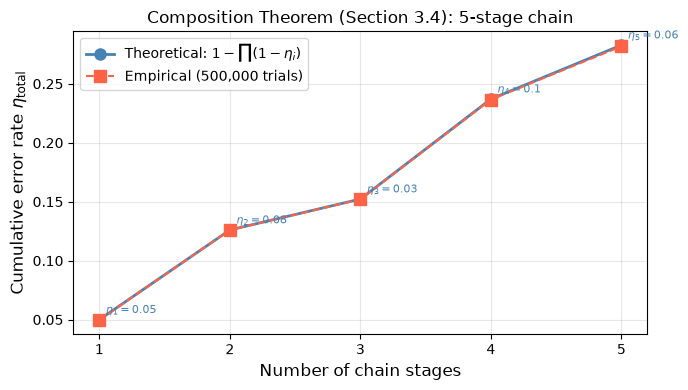


Composition theorem verified: empirical closely matches theory at each stage.


In [7]:
# Plot: cumulative error rate as stages are added to the chain
eta_cumulative_theory = []
eta_cumulative_empirical = []
tnr_running = 1.0

output_running = np.full(N_COMP, fill_value=True, dtype=bool)
for i, eta in enumerate(eta_stages):
    corrupt = rng.uniform(size=N_COMP) < eta
    output_running = output_running & ~corrupt   # True input: a corrupted value stays False
    tnr_running *= (1.0 - eta)
    eta_cumulative_theory.append(1.0 - tnr_running)
    eta_cumulative_empirical.append(1.0 - np.mean(output_running))

stages = list(range(1, k + 1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(stages, eta_cumulative_theory, "o-", color="steelblue", linewidth=2,
        markersize=8, label="Theoretical: $1 - \\prod(1 - \\eta_i)$")
ax.plot(stages, eta_cumulative_empirical, "s--", color="tomato", linewidth=1.5,
        markersize=8, label=f"Empirical ({N_COMP:,} trials)")
ax.set_xlabel("Number of chain stages", fontsize=12)
ax.set_ylabel("Cumulative error rate $\\eta_{\\mathrm{total}}$", fontsize=12)
ax.set_title("Composition Theorem (Section 3.4): 5-stage chain", fontsize=12)
ax.legend(fontsize=10)
ax.set_xticks(stages)
for s, (th, emp) in enumerate(zip(eta_cumulative_theory, eta_cumulative_empirical), 1):
    ax.annotate(f"$\\eta_{s}={eta_stages[s-1]}$", xy=(s, th), xytext=(s + 0.05, th + 0.005),
                fontsize=8, color="steelblue")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

assert np.max(np.abs(np.array(eta_cumulative_empirical) - np.array(eta_cumulative_theory))) < 0.005
print("\nComposition theorem verified: empirical closely matches theory at each stage.")

## 4. Miller-Rabin Primality Testing

The Miller-Rabin primality test (Section 3.5) is a canonical example of `Bernoulli[bool]`
composition: each round with witness `a` is a single `Bernoulli[bool]` instance with
**FNR = 0** (a prime is never declared composite) and **FPR at most 1/4** (a composite
may be declared "probably prime" with probability at most 1/4).

Running `k` independent rounds AND-s the k results: declare composite only if any round
returns composite. A composite survives only if every round lies, so the false-positive
rates multiply: this is the dual product rule of Section 3.4 (the all-negative corner
of the AND), and with FNR = 0 it gives FPR_k at most `(1/4)^k`.

**Predicate recasting (Section 3.5 framing):** Rather than treating `n` as the input
and the witness pool as sampling, we recast the test as a predicate
`P_tilde: {2, ..., n-2} -> {composite, probably prime}` on the witness pool.
Distinct witnesses are distinct input elements, and Axiom 1's independence claim
is that error events at distinct witnesses are independent.

### The algorithm (~25 lines)

**Why 341 is instructive:** 341 = 11 x 31 is a Fermat pseudoprime to base 2:
`2^340 mod 341 = 1`, so the naive Fermat test is fooled. Miller-Rabin is stronger:
it checks for non-trivial square roots of 1, catching 341 with witness `a = 2`.

Working out: `n - 1 = 340 = 4 * 85 = 2^2 * 85`, so `d = 85`, `r = 2`.
Then `2^85 mod 341 = 32`. Neither 1 nor 340. One squaring: `32^2 mod 341 = 1024 mod 341 = 1`.
The value 1 appeared but from 32, not from 340; this is a non-trivial square root of 1,
which witnesses compositeness. Result: `composite`.

In [8]:
def miller_rabin(n: int, a: int) -> str:
    """One round of Miller-Rabin with witness a.

    Returns 'composite' (definitive) or 'probably prime' (uncertain).

    Characterization as Bernoulli[bool]:
      FNR = 0:    a prime n is never declared 'composite'.
      FPR <= 1/4: a composite n is declared 'probably prime' with
                  probability at most 1/4 per witness (Miller-Rabin theorem).
    """
    if n < 2 or n % 2 == 0:
        return 'composite' if n != 2 else 'probably prime'
    d, r = n - 1, 0
    while d % 2 == 0:
        d //= 2
        r += 1
    x = pow(a, d, n)
    if x == 1 or x == n - 1:
        return 'probably prime'
    for _ in range(r - 1):
        x = pow(x, 2, n)
        if x == n - 1:
            return 'probably prime'
    return 'composite'


def is_prime_mr(n: int, k: int = 20) -> str:
    """k-round Miller-Rabin test using k distinct random witnesses.

    Returns 'composite' if any round is definitive; 'probably prime' otherwise.
    FPR <= (1/4)^k by the composition theorem (Section 3.4).
    """
    if n < 2:
        return 'composite'
    if n == 2 or n == 3:
        return 'probably prime'
    if n % 2 == 0:
        return 'composite'
    witnesses = range(2, min(n - 1, k + 2))  # use first k witnesses starting from 2
    for a in witnesses:
        if miller_rabin(n, a) == 'composite':
            return 'composite'
    return 'probably prime'


# Verify 341: Fermat pseudoprime to base 2 that Miller-Rabin catches
n_test = 341
result_341 = miller_rabin(341, 2)
print(f"miller_rabin(341, 2) = '{result_341}'  (expected: 'composite')")
assert result_341 == 'composite', "FAIL: should have caught 341 as composite"
print(f"341 = {341 // 11} x {341 // 31} -- correctly identified as composite")
print()

# Stepped trace for 341
print("Step-by-step trace for n=341, a=2:")
print(f"  n - 1 = 340 = 2^2 * 85, so d=85, r=2")
x = pow(2, 85, 341)
print(f"  x = 2^85 mod 341 = {x}  (not 1, not 340)")
x2 = pow(x, 2, 341)
print(f"  x = x^2 mod 341 = {x2}  (is 1, but came from {x}, not 340)")
print(f"  Non-trivial square root of 1 detected -> 'composite'")
print()

# Test small primes
small_primes = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37]
print("Small primes (should all be 'probably prime' with enough witnesses):")
for p in small_primes:
    result = is_prime_mr(p, k=p - 2 if p > 3 else 1)
    status = "OK" if result == 'probably prime' else "FAIL"
    print(f"  is_prime_mr({p:>3d}) = '{result}'  [{status}]")
print()

# Test small composites
small_composites = [4, 6, 8, 9, 10, 12, 15, 21, 25, 49, 341, 561]
print("Small composites (should all be 'composite' with witness 2 or 3):")
for c in small_composites:
    for a in [2, 3, 5, 7]:
        if 1 < a < c - 1:
            result = miller_rabin(c, a)
            if result == 'composite':
                print(f"  miller_rabin({c:>4d}, {a}) = 'composite'  [correctly identified]")
                break
    else:
        print(f"  {c}: no witness in {{2,3,5,7}} found it composite (check manually)")

miller_rabin(341, 2) = 'composite'  (expected: 'composite')
341 = 31 x 11 -- correctly identified as composite

Step-by-step trace for n=341, a=2:
  n - 1 = 340 = 2^2 * 85, so d=85, r=2
  x = 2^85 mod 341 = 32  (not 1, not 340)
  x = x^2 mod 341 = 1  (is 1, but came from 32, not 340)
  Non-trivial square root of 1 detected -> 'composite'

Small primes (should all be 'probably prime' with enough witnesses):
  is_prime_mr(  2) = 'probably prime'  [OK]
  is_prime_mr(  3) = 'probably prime'  [OK]
  is_prime_mr(  5) = 'probably prime'  [OK]
  is_prime_mr(  7) = 'probably prime'  [OK]
  is_prime_mr( 11) = 'probably prime'  [OK]
  is_prime_mr( 13) = 'probably prime'  [OK]
  is_prime_mr( 17) = 'probably prime'  [OK]
  is_prime_mr( 19) = 'probably prime'  [OK]
  is_prime_mr( 23) = 'probably prime'  [OK]
  is_prime_mr( 29) = 'probably prime'  [OK]
  is_prime_mr( 31) = 'probably prime'  [OK]
  is_prime_mr( 37) = 'probably prime'  [OK]

Small composites (should all be 'composite' with witness 2 or

## 5. Empirical FPR_k vs Theoretical (1/4)^k

The composition theorem (Section 3.4) gives `FPR_k <= (1/4)^k` for `k` independent rounds.
Here we measure the empirical false-positive rate over a sample of random composites
for each `k` from 1 to 20, and plot against the theoretical bound.

A **false positive** occurs when `k` rounds all return 'probably prime' for a composite `n`:
i.e., the composite evades detection by all `k` witnesses. We use `k` witnesses chosen
uniformly at random from `{2, ..., n-2}` to match the independence assumption.

In [9]:
def gen_composites(n_samples: int, lo: int = 100, hi: int = 10_000,
                   rng: np.random.Generator = None) -> list:
    """Generate a list of confirmed composite integers in [lo, hi].

    Uses a simple deterministic primality sieve to confirm compositeness.
    """
    if rng is None:
        rng = np.random.default_rng()

    def is_definitely_prime(n: int) -> bool:
        """Trial division primality check (slow but certain for small n)."""
        if n < 2:
            return False
        if n == 2:
            return True
        if n % 2 == 0:
            return False
        for d in range(3, int(n**0.5) + 1, 2):
            if n % d == 0:
                return False
        return True

    composites = []
    candidates = rng.integers(lo, hi, size=n_samples * 10)
    for c in candidates:
        c = int(c)
        if not is_definitely_prime(c) and c >= 4:
            composites.append(c)
            if len(composites) == n_samples:
                break
    return composites


N_COMPOSITES = 3000
composites = gen_composites(N_COMPOSITES, rng=rng)
print(f"Generated {len(composites)} confirmed composites in [100, 10000]")
print(f"Sample: {composites[:10]}")
print()

K_MAX = 20
k_values = list(range(1, K_MAX + 1))
emp_fpr = []
theory_bound = [(1.0 / 4.0) ** k for k in k_values]

for k in k_values:
    false_positives = 0
    for n in composites:
        # Draw k witnesses uniformly at random from {2, ..., n-2}
        if n <= 4:
            continue
        witnesses = rng.integers(2, n - 1, size=k)  # n-1 exclusive
        # False positive: all k rounds say 'probably prime'
        if all(miller_rabin(n, int(a)) == 'probably prime' for a in witnesses):
            false_positives += 1
    emp_fpr.append(false_positives / len(composites))

print(f"{'k':>4s}  {'Empirical FPR':>16s}  {'Theoretical (1/4)^k':>20s}")
print("-" * 45)
for k, emp, th in zip(k_values, emp_fpr, theory_bound):
    print(f"{k:>4d}  {emp:>16.8f}  {th:>20.8f}")

Generated 3000 confirmed composites in [100, 10000]
Sample: [8030, 1715, 9680, 8258, 8085, 9917, 9747, 5210, 9616, 205]



   k     Empirical FPR   Theoretical (1/4)^k
---------------------------------------------
   1        0.00166667            0.25000000
   2        0.00000000            0.06250000
   3        0.00000000            0.01562500
   4        0.00000000            0.00390625
   5        0.00000000            0.00097656
   6        0.00000000            0.00024414
   7        0.00000000            0.00006104
   8        0.00000000            0.00001526
   9        0.00000000            0.00000381
  10        0.00000000            0.00000095
  11        0.00000000            0.00000024
  12        0.00000000            0.00000006
  13        0.00000000            0.00000001
  14        0.00000000            0.00000000
  15        0.00000000            0.00000000
  16        0.00000000            0.00000000
  17        0.00000000            0.00000000
  18        0.00000000            0.00000000
  19        0.00000000            0.00000000
  20        0.00000000            0.00000000


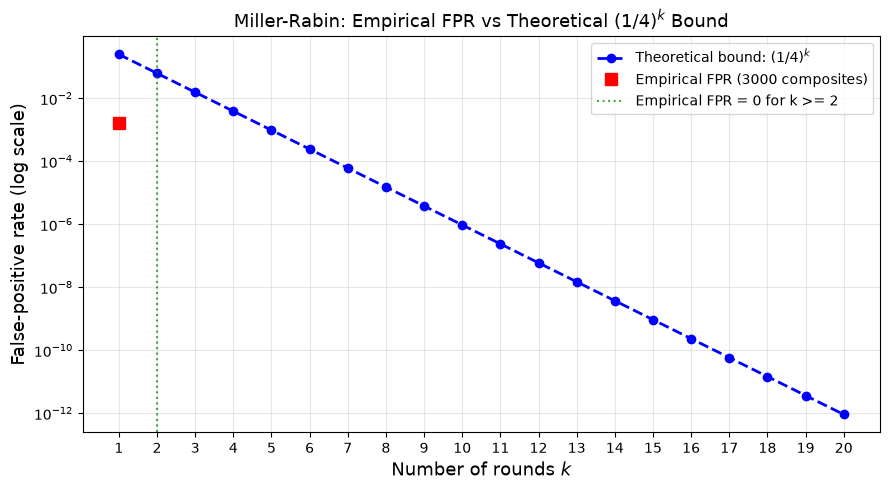


Observation: the empirical FPR drops below the theoretical bound.
The (1/4)^k bound is a worst-case guarantee; most composites are caught
much faster, because their strong-liar sets are smaller than n/4.


In [10]:
# Plot empirical FPR vs theoretical (1/4)^k on log scale
fig, ax = plt.subplots(figsize=(9, 5))

ax.semilogy(k_values, theory_bound, "b--o", linewidth=2, markersize=6,
            label=r"Theoretical bound: $(1/4)^k$")

# Plot only nonzero empirical FPR values
k_nonzero = [k for k, v in zip(k_values, emp_fpr) if v > 0]
fpr_nonzero = [v for v in emp_fpr if v > 0]
if k_nonzero:
    ax.semilogy(k_nonzero, fpr_nonzero, "rs", markersize=8,
                label=f"Empirical FPR ({N_COMPOSITES} composites)")

k_zero = [k for k, v in zip(k_values, emp_fpr) if v == 0]
if k_zero:
    ax.axvline(min(k_zero), color="green", linestyle=":", alpha=0.7,
               label=f"Empirical FPR = 0 for k >= {min(k_zero)}")

ax.set_xlabel("Number of rounds $k$", fontsize=13)
ax.set_ylabel("False-positive rate (log scale)", fontsize=13)
ax.set_title("Miller-Rabin: Empirical FPR vs Theoretical $(1/4)^k$ Bound", fontsize=13)
ax.legend(fontsize=10)
ax.set_xticks(k_values)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("Observation: the empirical FPR drops below the theoretical bound.")
print("The (1/4)^k bound is a worst-case guarantee; most composites are caught")
print("much faster, because their strong-liar sets are smaller than n/4.")

## 6. Open Question: What Happens with Dependent Witnesses?

The `(1/4)^k` composition bound relies on independence across witnesses.
Axiom 1 (Section 4.2, Chapter 4) asserts that error events at distinct input elements
are independent. For Miller-Rabin, this means: the event "witness `a_i` is a strong liar"
is independent of the event "witness `a_j` is a strong liar" for `i != j`.

In practice, the strong liars for a given composite `n` form the set
`SL(n) = {a : a is a strong liar for n}`. Witnesses drawn from this set are all liars.
If we corrupt the witness selection process and accidentally bias toward `SL(n)`,
the independence assumption breaks and the `(1/4)^k` bound may not hold.

This section demonstrates the effect of correlated witness selection.
A full treatment of when Axiom 1's independence assumption fails is deferred to Chapter 16
(negative space: when the framework breaks down).

In [11]:
def find_strong_liars(n: int) -> list:
    """Find all strong liars for n: witnesses a such that miller_rabin(n, a) = 'probably prime'.

    Only feasible for small n. Returns the list of strong liars in {2, ..., n-2}.
    """
    return [a for a in range(2, n - 1) if miller_rabin(n, a) == 'probably prime']


# Find a composite with a nontrivial strong-liar set to illustrate the effect
# Use n = 561 (the smallest Carmichael number; all bases coprime to 561 are Fermat liars)
# For Miller-Rabin specifically, 561's strong liar set is smaller than for Fermat
test_composites_sl = [341, 561, 645, 1105, 1729]

print("Strong-liar sets for selected composites:")
print(f"{'n':>6s}  {'|SL(n)|':>8s}  {'|SL(n)| / (n-3)':>16s}  {'Sample liars'}")
print("-" * 65)
for n in test_composites_sl:
    sl = find_strong_liars(n)
    ratio = len(sl) / (n - 3) if n > 4 else 0.0
    print(f"{n:>6d}  {len(sl):>8d}  {ratio:>16.4f}  {sl[:6]}{'...' if len(sl) > 6 else ''}")

Strong-liar sets for selected composites:
     n   |SL(n)|   |SL(n)| / (n-3)  Sample liars
-----------------------------------------------------------------
   341        48            0.1420  [4, 16, 29, 30, 46, 47]...
   561         8            0.0143  [50, 101, 103, 256, 305, 458]...
   645        12            0.0187  [16, 121, 194, 226, 254, 256]...
  1105        28            0.0254  [47, 72, 98, 123, 132, 242]...
  1729       160            0.0927  [9, 10, 12, 16, 69, 74]...


In [12]:
def empirical_fpr_correlated(n: int, k: int, n_trials: int,
                              strong_liars: list, bias: float,
                              rng: np.random.Generator) -> float:
    """Estimate FPR for k-round Miller-Rabin when witness selection is biased.

    With probability `bias`, each witness is drawn uniformly from strong_liars
    instead of uniformly from {2, ..., n-2}.

    bias=0.0: fully independent (standard test)
    bias=1.0: always selects from strong_liars (guaranteed false positive if |SL| > 0)
    """
    if not strong_liars:
        return 0.0
    fp_count = 0
    for _ in range(n_trials):
        # Draw k witnesses, each with probability `bias` from the strong-liar set
        all_pp = True
        for _ in range(k):
            if rng.uniform() < bias:
                a = int(rng.choice(strong_liars))
            else:
                a = int(rng.integers(2, n - 1))
            if miller_rabin(n, a) == 'composite':
                all_pp = False
                break
        if all_pp:
            fp_count += 1
    return fp_count / n_trials


# Use n=341 as the test composite
n_demo = 341
sl_demo = find_strong_liars(n_demo)
print(f"Demo composite: n = {n_demo}")
print(f"Strong-liar set SL({n_demo}): {sl_demo} (|SL| = {len(sl_demo)})")
print(f"SL fraction of witness pool: {len(sl_demo) / (n_demo - 3):.4f}")
print()

K_DEMO = 5
N_TRIALS_BIAS = 10_000
bias_levels = [0.0, 0.25, 0.50, 0.75, 1.0]
theoretical_independent = (1.0 / 4.0) ** K_DEMO
sl_fraction = len(sl_demo) / (n_demo - 3)
theory_uniform = sl_fraction ** K_DEMO

print(f"k = {K_DEMO} rounds")
print(f"Theoretical FPR (independent): (1/4)^{K_DEMO} = {theoretical_independent:.6f}")
print(f"Exact FPR for independent uniform witnesses: (|SL|/(n-3))^{K_DEMO} = {theory_uniform:.6f}")
print("Fully biased selection (every witness from SL): FPR = 1")
print()
print(f"{'Bias toward SL':>16s}  {'Empirical FPR':>16s}")
print("-" * 36)
for bias in bias_levels:
    fpr = empirical_fpr_correlated(n_demo, K_DEMO, N_TRIALS_BIAS, sl_demo, bias, rng)
    print(f"  {bias:>12.2f}      {fpr:>16.6f}")

Demo composite: n = 341
Strong-liar set SL(341): [4, 16, 29, 30, 46, 47, 54, 61, 64, 70, 78, 85, 97, 116, 120, 123, 125, 126, 139, 151, 153, 157, 159, 163, 178, 182, 184, 188, 190, 202, 215, 216, 218, 221, 225, 244, 256, 263, 271, 277, 280, 287, 294, 295, 311, 312, 325, 337] (|SL| = 48)
SL fraction of witness pool: 0.1420

k = 5 rounds
Theoretical FPR (independent): (1/4)^5 = 0.000977
Exact FPR for independent uniform witnesses: (|SL|/(n-3))^5 = 0.000058
Fully biased selection (every witness from SL): FPR = 1

  Bias toward SL     Empirical FPR
------------------------------------
          0.00              0.000100
          0.25              0.006500


          0.50              0.062400


          0.75              0.296300


          1.00              1.000000


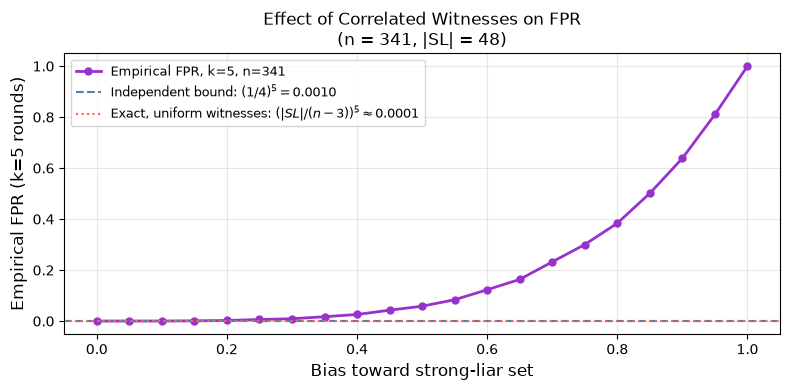


Observation: with zero bias (independent witnesses), the FPR matches or beats the
(1/4)^k theoretical bound. As bias toward the strong-liar set increases, the FPR
rises above the bound. The independence assumption underlying Axiom 1 is doing real work.

Chapter 16 will examine the general case: when the independence structure of the
Bernoulli framework breaks down and the (1/4)^k guarantee no longer applies.


In [13]:
# Plot FPR vs bias level
bias_grid = np.linspace(0.0, 1.0, 21)
fpr_vs_bias = [empirical_fpr_correlated(n_demo, K_DEMO, N_TRIALS_BIAS, sl_demo, b, rng)
               for b in bias_grid]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(bias_grid, fpr_vs_bias, "o-", color="darkorchid", linewidth=2, markersize=5,
        label=f"Empirical FPR, k={K_DEMO}, n={n_demo}")
ax.axhline(theoretical_independent, color="steelblue", linestyle="--", linewidth=1.5,
           label=f"Independent bound: $(1/4)^{{{K_DEMO}}} = {theoretical_independent:.4f}$")
ax.axhline(theory_uniform, color="tomato", linestyle=":", linewidth=1.5,
           label=f"Exact, uniform witnesses: $(|SL|/(n{-3}))^{{{K_DEMO}}} \\approx {theory_uniform:.4f}$")
ax.set_xlabel("Bias toward strong-liar set", fontsize=12)
ax.set_ylabel(f"Empirical FPR (k={K_DEMO} rounds)", fontsize=12)
ax.set_title(f"Effect of Correlated Witnesses on FPR\n(n = {n_demo}, |SL| = {len(sl_demo)})",
             fontsize=12)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("Observation: with zero bias (independent witnesses), the FPR matches or beats the")
print("(1/4)^k theoretical bound. As bias toward the strong-liar set increases, the FPR")
print("rises above the bound. The independence assumption underlying Axiom 1 is doing real work.")
print()
print("Chapter 16 will examine the general case: when the independence structure of the")
print("Bernoulli framework breaks down and the (1/4)^k guarantee no longer applies.")

## Closing: Cross-References and Next Steps

**Chapter 3** establishes the Boolean-algebra layer of the Bernoulli framework:
AND, OR, NOT under noise; exact propagation through formulas one latent assignment
at a time; the composition theorem; and Miller-Rabin as the
worked climax that unifies the framework with a classical algorithm.

**Chapter 4** (Axioms and Kronecker Product) develops the formal axioms
that Chapter 3 invoked informally, and presents the Kronecker-product composition
for parallel (rather than serial) channel queries. Chapter 4 is a theory-intensive
chapter by design and does not have a paired notebook. The material in Chapter 4
is foundational rather than computational; the key results (Axioms 1 and 2,
the Kronecker theorem) are stated and proved in the text without requiring
numerical simulation.

**Chapter 5** (Approximate Sets) is the first Part II chapter. Its notebook
(`ch05-approximate-sets.ipynb`) implements Bloom filters
as a direct application of the Boolean composition framework from Chapter 3.

**Summary of what this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| 3.1 AND truth table | Case-by-case probability matches closed form | Yes (200k trials) |
| 3.2 NOT | FPR and FNR swap; double NOT is identity | Yes |
| 3.2 OR | De Morgan derivation matches direct truth table | Yes |
| 3.3 Formulas | A rate pair does not compose: six error regimes for $(b_0 \land b_1) \lor b_2$; exact $0.03764$ vs summary $0.020392$ at $w = 010$; worst pair bounded by the recursive bound | Yes (exact, plus 200k trials) |
| 3.4 Composition theorem | `eta_total = 1 - prod(1 - eta_i)` on 5-stage chain | Yes (500k trials) |
| 3.5 Miller-Rabin | `miller_rabin(341, 2) = 'composite'` | Yes |
| 3.5 FPR bound | Empirical FPR_k at most `(1/4)^k` for k=1..20 | Yes (3000 composites) |
| 3.5 Dependence | Biased witnesses raise FPR above the bound | Demonstrated |